# BIO AI Mini project — Training Model

This is the single script that runs the ENTIRE BIO AI backend pipeline,
start to finish, using only data/ml_model_features.csv:

    1. Load and inspect the dataset.
    2. Run data-quality checks and save data_quality_report.csv.
    3. Run exploratory data analysis (EDA) and save chart images.
    4. Save a copy of the full dataset as integrated_bioai_database.csv
       — this is the single "evidence database" that Layer 1 (evidence
       retrieval) searches.
    5. Train and compare several ML models (Layer 2).
    6. Evaluate every model and save model_evaluation_report.csv.
    7. Select the best model and save it, together with its
       preprocessing pipeline, as trained_bioai_model.joblib.
    8. Save model_metadata.json describing the model honestly.
    9. Compute permutation feature importance (explainability) and save
       it to a CSV file.
    10. Run a small example of candidate ranking and save
        candidate_ranking_results.csv.

## Importing all necessary libraries

In [2]:
!pip install -q scikit-learn pandas joblib matplotlib seaborn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 77.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 93.4 MB/s eta 0:00:00


## Upload the dataset

In [3]:
from google.colab import files

print("Choose ml_model_features.csv from your computer...")
uploaded = files.upload()

Choose ml_model_features.csv from your computer...


Saving ml_model_features.csv to ml_model_features.csv


## Load and inspect the dataset

In [4]:
import pandas as pd

DATA_PATH = "ml_model_features.csv"
data = pd.read_csv(DATA_PATH)

print("Shape:", data.shape)
print("\nColumns:", list(data.columns))
print("\nFirst 5 rows:")
data.head()

Shape: (5468, 11)

Columns: ['Row_ID', 'Group_ID', 'Split', 'Disease', 'Gene', 'Variant', 'Drug', 'Variant_Type', 'N_Alleles', 'Drug_Is_Combination', 'Association_Label']

First 5 rows:


,Row_ID,Group_ID,Split,Disease,Gene,Variant,Drug,Variant_Type,N_Alleles,Drug_Is_Combination,Association_Label
0,1,GSTP1 || rs1695,train,ovarian cancer,GSTP1,rs1695,carboplatin,rsid,1,0,0
1,2,SLCO1B3 || rs4149117,train,lung cancer,SLCO1B3,rs4149117,erlotinib,rsid,1,0,0
2,3,RXRA || rs62576288,test,nasopharyngeal cancer,RXRA,rs62576288,conjugated estrogens,rsid,1,0,0
3,4,ABCG2 || rs2725252,train,chronic myeloid leukemia (cml),ABCG2,rs2725252,pitrakinra,rsid,1,0,0
4,5,ATIC || rs16853826,test,rheumatoid arthritis,ATIC,rs16853826,infliximab,rsid,1,0,0


## Data quality checks

In [5]:
print("Data types:\n", data.dtypes)

print("\nMissing values per column:\n", data.isna().sum())

print("\nDuplicate rows (excluding Row_ID):",
      data.drop(columns=["Row_ID"]).duplicated().sum())

print("\nUnique counts:")
for col in ["Disease", "Gene", "Variant", "Drug"]:
    print(f"  {col}: {data[col].nunique()} unique values")

print("\nAssociation_Label distribution:\n", data["Association_Label"].value_counts())

# Check for conflicting labels: same Disease+Gene+Variant+Drug combo
# labelled both 0 and 1 in different rows.
conflict_check = (
    data.groupby(["Disease", "Gene", "Variant", "Drug"])["Association_Label"]
    .nunique()
)
print("\nConflicting-label combinations:", (conflict_check > 1).sum())

# Leakage check: does every Gene+Variant group stay inside one split only?
if "Group_ID" in data.columns and "Split" in data.columns:
    groups_per_split = data.groupby("Group_ID")["Split"].nunique()
    leaking_groups = (groups_per_split > 1).sum()
    print("\nGroups leaking across train/test:", leaking_groups)
    print("Split counts:\n", data["Split"].value_counts())

Data types:
 Row_ID                  int64
Group_ID               object
Split                  object
Disease                object
Gene                   object
Variant                object
Drug                   object
Variant_Type           object
N_Alleles               int64
Drug_Is_Combination     int64
Association_Label       int64
dtype: object

Missing values per column:
 Row_ID                 0
Group_ID               0
Split                  0
Disease                0
Gene                   0
Variant                0
Drug                   0
Variant_Type           0
N_Alleles              0
Drug_Is_Combination    0
Association_Label      0
dtype: int64

Duplicate rows (excluding Row_ID): 0

Unique counts:
  Disease: 42 unique values
  Gene: 348 unique values
  Variant: 667 unique values
  Drug: 164 unique values

Association_Label distribution:
 Association_Label
0    4101
1    1367
Name: count, dtype: int64

Conflicting-label combinations: 0

Groups leaking across train/t

## Exploratory Data Analysis (EDA)

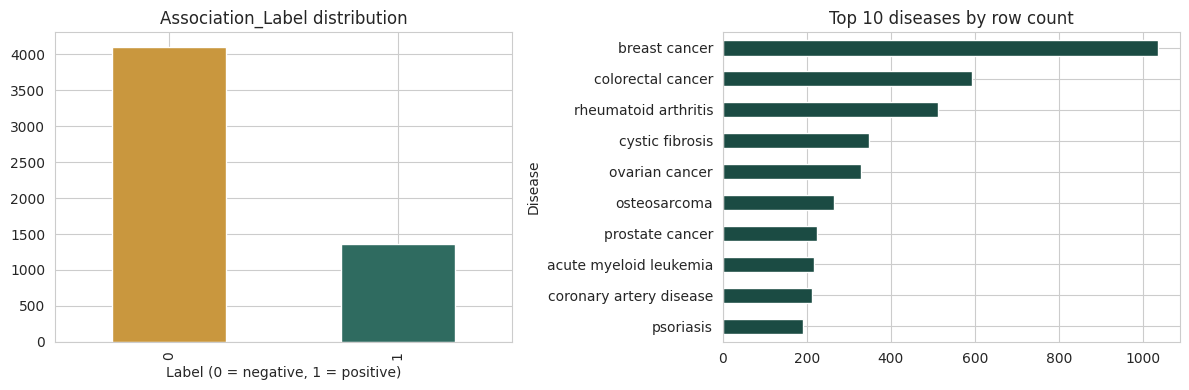

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data["Association_Label"].value_counts().plot(kind="bar", ax=axes[0], color=["#C9973E", "#2F6B60"])
axes[0].set_title("Association_Label distribution")
axes[0].set_xlabel("Label (0 = negative, 1 = positive)")

data["Disease"].value_counts().head(10).plot(kind="barh", ax=axes[1], color="#1B4B43")
axes[1].set_title("Top 10 diseases by row count")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## Train / test split (using the dataset’s own Split column)

Why use the existing Split column instead of a random split? Because we verified in Cell 4 that it already keeps every Gene+Variant group entirely inside one split — re-splitting randomly would only risk leaking related rows between train and test.

In [7]:
INPUT_FEATURES = ["Disease", "Gene", "Variant", "Drug"]
TARGET_COLUMN = "Association_Label"

train_data = data[data["Split"] == "train"].copy()
test_data = data[data["Split"] == "test"].copy()

X_train = train_data[INPUT_FEATURES]
y_train = train_data[TARGET_COLUMN]
X_test = test_data[INPUT_FEATURES]
y_test = test_data[TARGET_COLUMN]

print("Train rows:", len(X_train), " Test rows:", len(X_test))


Train rows: 4308  Test rows: 1160


## Build the preprocessing + model pipeline, train all candidates

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

RANDOM_SEED = 42

def build_pipeline(model):
    preprocessing = ColumnTransformer([
        ("encode_categories", OneHotEncoder(handle_unknown="ignore"), INPUT_FEATURES)
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

candidate_models = {
    "baseline_most_frequent": DummyClassifier(strategy="most_frequent", random_state=RANDOM_SEED),
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    "random_forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    "extra_trees": ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    "gradient_boosting": GradientBoostingClassifier(random_state=RANDOM_SEED),
}

fitted_pipelines = {}
for name, model in candidate_models.items():
    print(f"Training {name} ...")
    pipeline = build_pipeline(model)
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline

print("Done training all models.")

Training baseline_most_frequent ...
Training logistic_regression ...
Training random_forest ...
Training extra_trees ...
Training gradient_boosting ...
Done training all models.


## Evaluate every model

In [11]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

all_metrics = []
for name, pipeline in fitted_pipelines.items():
    predicted_labels = pipeline.predict(X_test)
    predicted_scores = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None

    tn, fp, fn, tp = confusion_matrix(y_test, predicted_labels, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")

    metrics = {
        "model_name": name,
        "accuracy": accuracy_score(y_test, predicted_labels),
        "precision": precision_score(y_test, predicted_labels, zero_division=0),
        "recall": recall_score(y_test, predicted_labels, zero_division=0),
        "f1_score": f1_score(y_test, predicted_labels, zero_division=0),
        "specificity": specificity,
        "roc_auc": roc_auc_score(y_test, predicted_scores) if predicted_scores is not None else None,
        "pr_auc": average_precision_score(y_test, predicted_scores) if predicted_scores is not None else None,
    }
    all_metrics.append(metrics)

evaluation_report = pd.DataFrame(all_metrics)
evaluation_report.to_csv("model_evaluation_report.csv", index=False)
evaluation_report

,model_name,accuracy,precision,recall,f1_score,specificity,roc_auc,pr_auc
0,baseline_most_frequent,0.750000,0.000000,0.000000,0.000000,1.000000,0.500000,0.250000
1,logistic_regression,0.775862,0.607143,0.293103,0.395349,0.936782,0.731851,0.502869
2,random_forest,0.823276,0.734807,0.458621,0.564756,0.944828,0.817212,0.686795
3,extra_trees,0.849138,0.757848,0.582759,0.658869,0.937931,0.820268,0.712900
4,gradient_boosting,0.799138,0.782178,0.272414,0.404092,0.974713,0.744231,0.547275


## Select the best model and save it

In [12]:
import joblib
import json

# Pick the best model by ROC-AUC, excluding the baseline (which only
# exists for comparison).
comparable = evaluation_report[evaluation_report["model_name"] != "baseline_most_frequent"]
best_row = comparable.sort_values(by="roc_auc", ascending=False).iloc[0]
best_model_name = best_row["model_name"]
best_pipeline = fitted_pipelines[best_model_name]

print("Best model:", best_model_name)

joblib.dump(best_pipeline, "trained_bioai_model.joblib")

metadata = {
    "model_name": best_model_name,
    "target_column": TARGET_COLUMN,
    "input_features": INPUT_FEATURES,
    "data_source": "ml_model_features.csv (only dataset used)",
    "target_definition": (
        "1 = positive association example in the dataset's construction, "
        "0 = negative example. A label of 0 does not necessarily mean the "
        "drug is clinically ineffective."
    ),
    "selected_model_metrics": best_row.to_dict(),
    "limitations": [
        "Trained on one dataset and one split; may not generalize.",
        "A high score means statistical similarity to positive training "
        "examples, not proof of clinical effectiveness.",
    ],
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved trained_bioai_model.joblib and model_metadata.json")

Best model: extra_trees
Saved trained_bioai_model.joblib and model_metadata.json


## Explainability: permutation feature importance

In [13]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=10,
    random_state=RANDOM_SEED, scoring="roc_auc", n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "mean_importance_roc_auc_drop": result.importances_mean,
    "std_importance": result.importances_std,
}).sort_values(by="mean_importance_roc_auc_drop", ascending=False)

importance_df.to_csv("explainability_permutation_importance.csv", index=False)
importance_df

,feature,mean_importance_roc_auc_drop,std_importance
3,Drug,0.312861,0.018895
0,Disease,0.087352,0.008809
1,Gene,0.068717,0.005049
2,Variant,0.003183,0.000603


#### The model has essentially learned “certain Drug names tend to co-occur with positive labels, certain ones with negative” far more than it’s learned anything from Gene or Variant.
#### Variant being almost 0 is worth flagging in your report/presentation — it suggests the model isn’t really learning variant-specific pharmacogenomic patterns, just broader Drug/Disease associations. That’s a real limitation worth stating explicitly

## Layer 1: Evidence Search function

In [16]:
DISPLAY_COLUMNS = [
    "Disease",
    "Gene",
    "Variant",
    "Variant_Type",
    "Drug",
    "N_Alleles",
    "Drug_Is_Combination",
    "Association_Label",
]

def search_biological_records(df, disease=None, gene=None, variant=None, drug=None,
                                association_label=None, exact_match=False):
    mask = pd.Series(True, index=df.index)
    terms = {"Disease": disease, "Gene": gene, "Variant": variant, "Drug": drug}

    for col, term in terms.items():
        if term is None or str(term).strip() == "":
            continue
        col_values = df[col].astype(str).str.lower()
        search_text = str(term).strip().lower()
        if exact_match:
            mask &= (col_values == search_text)
        else:
            mask &= col_values.str.contains(search_text, regex=False, na=False)

    if association_label is not None:
        mask &= (df["Association_Label"] == association_label)

    results = df[mask].copy()

    # Only keep the agreed-upon columns, and only the ones that actually
    # exist in the dataframe (avoids a KeyError if a column is missing).
    columns_to_show = [col for col in DISPLAY_COLUMNS if col in results.columns]
    results = results[columns_to_show]

    return results, len(results)


# Example: search using only ONE field (a gene name)
results, count = search_biological_records(data, gene="CYP2D6")
print(f"Found {count} matching records")
results.head()

Found 12 matching records


,Disease,Gene,Variant,Variant_Type,Drug,N_Alleles,Drug_Is_Combination,Association_Label
505,breast cancer,CYP2D6,CYP2D6*1; CYP2D6*2; CYP2D6*3; CYP2D6*4; CYP2D6...,star_allele,tamoxifen,15,0,1
708,alzheimer's disease,CYP2D6,CYP2D6*1; CYP2D6*1xN; CYP2D6*3; CYP2D6*4; CYP2...,star_allele,donepezil,6,0,1
795,breast cancer,CYP2D6,CYP2D6*1; CYP2D6*2; CYP2D6*3; CYP2D6*4; CYP2D6...,star_allele,raloxifene,11,0,0
1526,breast cancer,CYP2D6,CYP2D6*1; CYP2D6*2; CYP2D6*3; CYP2D6*4; CYP2D6...,star_allele,antineoplastic agents,15,0,0
2282,breast cancer,CYP2D6,CYP2D6*1; CYP2D6*2; CYP2D6*3; CYP2D6*4; CYP2D6...,star_allele,anthracyclines and related substances,11,0,0


## Layer 2: Predict one combination

In [17]:
def predict_association(disease, gene, variant, drug, pipeline):
    for name, value in [("Disease", disease), ("Gene", gene), ("Variant", variant), ("Drug", drug)]:
        if value is None or str(value).strip() == "":
            return {"error": f"Missing required field: {name}"}

    candidate_df = pd.DataFrame([{"Disease": disease, "Gene": gene, "Variant": variant, "Drug": drug}])
    predicted_label = int(pipeline.predict(candidate_df)[0])
    predicted_score = float(pipeline.predict_proba(candidate_df)[0, 1]) if hasattr(pipeline, "predict_proba") else None

    return {
        "Disease": disease, "Gene": gene, "Variant": variant, "Drug": drug,
        "Predicted_Label": predicted_label,
        "Predicted_Association_Score": predicted_score,
    }


# Example
result = predict_association("breast cancer", "CYP2D6", "rs3892097", "Tamoxifen", best_pipeline)
result

{'Disease': 'breast cancer',
 'Gene': 'CYP2D6',
 'Variant': 'rs3892097',
 'Drug': 'Tamoxifen',
 'Predicted_Label': 0,
 'Predicted_Association_Score': 0.215}

## Layer 2: Rank a list of candidates

In [18]:
def rank_candidate_combinations(candidates, pipeline):
    rows = [predict_association(c["Disease"], c["Gene"], c["Variant"], c["Drug"], pipeline) for c in candidates]
    results_df = pd.DataFrame(rows)
    results_df = results_df.sort_values(by="Predicted_Association_Score", ascending=False, na_position="last").reset_index(drop=True)
    results_df["Ranking"] = results_df.index + 1
    return results_df


candidates = [
    {"Disease": "breast cancer", "Gene": "CYP2D6", "Variant": "rs3892097", "Drug": "Tamoxifen"},
    {"Disease": "breast cancer", "Gene": "CYP2D6", "Variant": "rs3892097", "Drug": "Letrozole"},
]
ranked = rank_candidate_combinations(candidates, best_pipeline)
ranked.to_csv("candidate_ranking_results.csv", index=False)
ranked

,Disease,Gene,Variant,Drug,Predicted_Label,Predicted_Association_Score,Ranking
0,breast cancer,CYP2D6,rs3892097,Tamoxifen,0,0.215,1
1,breast cancer,CYP2D6,rs3892097,Letrozole,0,0.215,2


## Download your trained artifacts

In [19]:
from google.colab import files

files.download("trained_bioai_model.joblib")
files.download("model_metadata.json")
files.download("model_evaluation_report.csv")
files.download("explainability_permutation_importance.csv")
files.download("candidate_ranking_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>